## Analysis the Extreme Event

In [1]:
# =========================
# Standard libraries
# =========================
import os
import json
import random
import pickle
import warnings
import math
import re

from datetime import datetime

warnings.filterwarnings("ignore")


# =========================
# Data processing
# =========================
import numpy as np
import pandas as pd
import geopandas as geopd


# =========================
# Geometry / GIS
# =========================
import shapely.wkt as wkt

from shapely.geometry import LineString, Polygon, Point

import mapclassify


# =========================
# Visualization
# =========================
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors

from matplotlib import cm
from matplotlib.colors import (
    LinearSegmentedColormap,
    BoundaryNorm,
    Normalize,
)
from matplotlib.colorbar import ColorbarBase
from mpl_toolkits.axes_grid1 import make_axes_locatable



# =========================
# Display settings
# =========================
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",   # Prefer if installed
        "Liberation Serif",  # Common on Ubuntu / Debian
        "Nimbus Roman",      # Common with TeX / Ghostscript
        "DejaVu Serif"       # Matplotlib fallback
    ],
    "mathtext.fontset": "stix",       # Math symbols closer to Times
    "axes.unicode_minus": False,
})

pd.set_option("display.max_columns", None)

## 给出大致的地理位置

In [2]:
## tractID 1700  rich
## tractID 2104  poor
## tractID 1802  middle

## 当前的波动是怎么样的？

In [23]:
df = pd.read_pickle('../../Data/e2018.pkl')
df.rename(columns={'BADGE':'badge'},inplace=True)
df.rename(columns={'DATE_RD':'date'},inplace=True)
df1 = pd.read_csv("../../Data/household_data/badge_location.csv")
df = pd.merge(df,df1[['badge','tractID','blockID']],on='badge',how='left')

In [24]:
df['badge'].nunique()

61672

In [4]:
TRACT_RICH = 1700
TRACT_POOR = 2104
TRACT_MIDDLE = 1802
# 建议统一成可比较的整数（避免 float / 字符串）
t = pd.to_numeric(df["tractID"], errors="coerce").astype("Int64")
df_tract_rich = df.loc[t == TRACT_RICH].copy()
df_tract_poor = df.loc[t == TRACT_POOR].copy()
df_tract_middle = df.loc[t == TRACT_MIDDLE].copy()

In [5]:
df_tract_rich.head()

,badge,date,INT_VALUE_0000,INT_VALUE_0030,INT_VALUE_0100,INT_VALUE_0130,INT_VALUE_0200,INT_VALUE_0230,INT_VALUE_0300,INT_VALUE_0330,INT_VALUE_0400,INT_VALUE_0430,INT_VALUE_0500,INT_VALUE_0530,INT_VALUE_0600,INT_VALUE_0630,INT_VALUE_0700,INT_VALUE_0730,INT_VALUE_0800,INT_VALUE_0830,INT_VALUE_0900,INT_VALUE_0930,INT_VALUE_1000,INT_VALUE_1030,INT_VALUE_1100,INT_VALUE_1130,INT_VALUE_1200,INT_VALUE_1230,INT_VALUE_1300,INT_VALUE_1330,INT_VALUE_1400,INT_VALUE_1430,INT_VALUE_1500,INT_VALUE_1530,INT_VALUE_1600,INT_VALUE_1630,INT_VALUE_1700,INT_VALUE_1730,INT_VALUE_1800,INT_VALUE_1830,INT_VALUE_1900,INT_VALUE_1930,INT_VALUE_2000,INT_VALUE_2030,INT_VALUE_2100,INT_VALUE_2130,INT_VALUE_2200,INT_VALUE_2230,INT_VALUE_2300,INT_VALUE_2330,address,district,tractID,blockID
19715,E163218,2018-01-01,0.07,0.06,0.08,0.04,0.17,0.32,0.64,1.07,3.77,4.50,4.84,1.36,1.29,1.04,0.07,0.08,0.06,0.06,0.07,0.06,0.26,0.52,0.43,0.50,1.08,1.16,1.37,4.26,4.83,4.94,1.92,1.58,1.03,1.30,1.44,1.04,1.32,1.32,1.07,1.32,1.29,1.05,0.07,0.14,0.05,0.50,0.60,0.72,8.0,POINT (-84.24873 30.47384),1700.0,4002.0
19716,E163218,2018-01-02,0.75,0.79,0.87,1.04,1.24,1.11,1.06,3.50,5.16,5.14,5.16,4.20,3.92,2.90,0.08,0.09,0.50,0.74,0.80,0.87,0.91,1.00,0.93,0.93,1.42,1.32,1.68,5.17,5.84,5.17,1.91,1.85,1.76,2.18,4.05,4.01,2.42,2.38,1.99,2.25,2.36,2.13,1.78,1.35,1.47,1.77,1.90,2.16,8.0,POINT (-84.24873 30.47384),1700.0,4002.0
19717,E163218,2018-01-03,2.07,2.09,2.02,2.01,2.16,2.03,2.19,3.64,5.42,7.22,5.29,4.24,3.88,4.29,3.52,3.35,3.91,4.25,3.55,2.20,2.61,3.10,2.49,2.21,3.07,4.07,2.50,2.03,1.56,1.87,2.77,2.83,1.38,1.15,2.52,1.99,1.51,1.46,1.70,2.10,2.14,1.88,1.66,1.37,1.44,1.51,1.85,2.09,8.0,POINT (-84.24873 30.47384),1700.0,4002.0
19718,E163218,2018-01-04,1.98,1.91,2.02,1.94,2.40,2.18,2.26,4.73,6.35,6.67,5.38,3.97,5.31,5.08,2.85,3.26,3.56,2.97,3.86,2.56,3.03,2.68,2.12,2.02,2.06,1.87,2.00,1.64,1.59,1.92,1.99,1.21,0.92,1.95,2.39,1.53,1.54,3.06,2.16,1.88,2.20,2.01,1.39,1.41,1.37,1.32,1.73,1.86,8.0,POINT (-84.24873 30.47384),1700.0,4002.0
19719,E163218,2018-01-05,1.92,1.94,1.96,2.02,2.05,2.39,2.50,5.45,5.44,7.07,5.73,4.17,4.22,5.63,3.61,3.23,5.54,4.26,2.57,4.51,3.78,3.55,2.28,1.95,1.49,1.63,1.40,1.50,1.72,1.24,1.37,1.33,0.94,1.85,1.56,1.13,0.80,1.39,1.34,1.04,1.76,1.82,1.34,1.38,1.29,1.56,1.65,2.05,8.0,POINT (-84.24873 30.47384),1700.0,4002.0


In [6]:
print(df_tract_rich['badge'].nunique())
print(df_tract_poor['badge'].nunique())
print(df_tract_middle['badge'].nunique())

2612
1204
1374


## 月份 10月份

In [8]:
import re
import numpy as np
import pandas as pd

# 与原来一致：EXPECTED_DAYS = 31, value_cols, N_COLS 已在前面定义

# 2018-10 共 31 个日历日（按日对齐）
OCT_FULL_INDEX = pd.date_range("2018-10-01", "2018-10-31", freq="D")
EXPECTED_DAYS = 31
value_cols = sorted(
    [c for c in df_tract_rich.columns if re.match(r"INT_VALUE_\d{4}", c)],
    key=lambda c: int(c.split("_")[-1]),
)
N_COLS = EXPECTED_DAYS * len(value_cols)  # 31 * 48 = 1488

MIN_DAYS = 29  # 缺最多 2 天 → 至少 29 天有数；缺失天用 0 补齐


def tract_to_october_hour_wide(tract_df: pd.DataFrame) -> pd.DataFrame:
    """
    10 月内 (badge,date) 去重后：
      - 不同日期数 < 29 的户丢弃；
      - 29/30/31 天保留，缺的天在全日 48 列上填 0，再拼成 31×48。
    """
    d = tract_df.loc[
        (tract_df["date"] >= "2018-10-01") & (tract_df["date"] <= "2018-10-31")
    ].copy()
    if d.empty:
        return pd.DataFrame(columns=["badge"] + [f"oct_h{i:04d}" for i in range(N_COLS)])

    d["date"] = pd.to_datetime(d["date"], errors="coerce").dt.normalize()
    d = d.drop_duplicates(subset=["badge", "date"], keep="first")

    rows = []
    for badge, g in d.groupby("badge"):
        n = g["date"].nunique()
        if n < MIN_DAYS:
            continue

        g = g.set_index("date").sort_index()
        g = g.reindex(OCT_FULL_INDEX)
        g[value_cols] = g[value_cols].apply(pd.to_numeric, errors="coerce").fillna(0.0)

        flat = g[value_cols].to_numpy(dtype=float, copy=False).ravel()
        if flat.size != N_COLS:
            raise ValueError(f"badge {badge}: 展平长度 {flat.size}，期望 {N_COLS}")
        rows.append(np.concatenate(([badge], flat)))

    col_names = ["badge"] + [f"oct_h{i:04d}" for i in range(N_COLS)]
    return pd.DataFrame(rows, columns=col_names)


df_tract_rich_half_hour = tract_to_october_hour_wide(df_tract_rich)
df_tract_poor_half_hour = tract_to_october_hour_wide(df_tract_poor)
df_tract_middle_half_hour = tract_to_october_hour_wide(df_tract_middle)

In [9]:
print(df_tract_rich_half_hour['badge'].nunique())
print(df_tract_poor_half_hour['badge'].nunique())
print(df_tract_middle_half_hour['badge'].nunique())

1094
579
1199


In [10]:
import numpy as np

def add_row_missing_and_zero_ratio(df: pd.DataFrame, col_prefix: str = "oct_h") -> pd.DataFrame:
    out = df.copy()
    val_cols = [c for c in out.columns if c.startswith(col_prefix)]
    if not val_cols:
        raise ValueError("未找到半点列（默认 oct_h 前缀）")

    X = out[val_cols].to_numpy(dtype=float, copy=False)

    out["halfhour_missing_ratio"] = np.isnan(X).mean(axis=1)
    out["halfhour_zero_ratio"] = np.mean(X == 0, axis=1)   # 含 NaN 的格子里，(X==0) 为 False
    return out


df_tract_rich_half_hour = add_row_missing_and_zero_ratio(df_tract_rich_half_hour)
df_tract_poor_half_hour = add_row_missing_and_zero_ratio(df_tract_poor_half_hour)
df_tract_middle_half_hour = add_row_missing_and_zero_ratio(df_tract_middle_half_hour)

In [11]:
THRESH = 0.15  # 15%
df_tract_rich_half_hour = df_tract_rich_half_hour.loc[
    df_tract_rich_half_hour["halfhour_zero_ratio"] < THRESH
].copy()
df_tract_poor_half_hour = df_tract_poor_half_hour.loc[
    df_tract_poor_half_hour["halfhour_zero_ratio"] < THRESH
].copy()
df_tract_middle_half_hour = df_tract_middle_half_hour.loc[
    df_tract_middle_half_hour["halfhour_zero_ratio"] < THRESH
].copy()

In [12]:
print(df_tract_rich_half_hour['badge'].nunique())
print(df_tract_poor_half_hour['badge'].nunique())
print(df_tract_middle_half_hour['badge'].nunique())

1053
528
1122


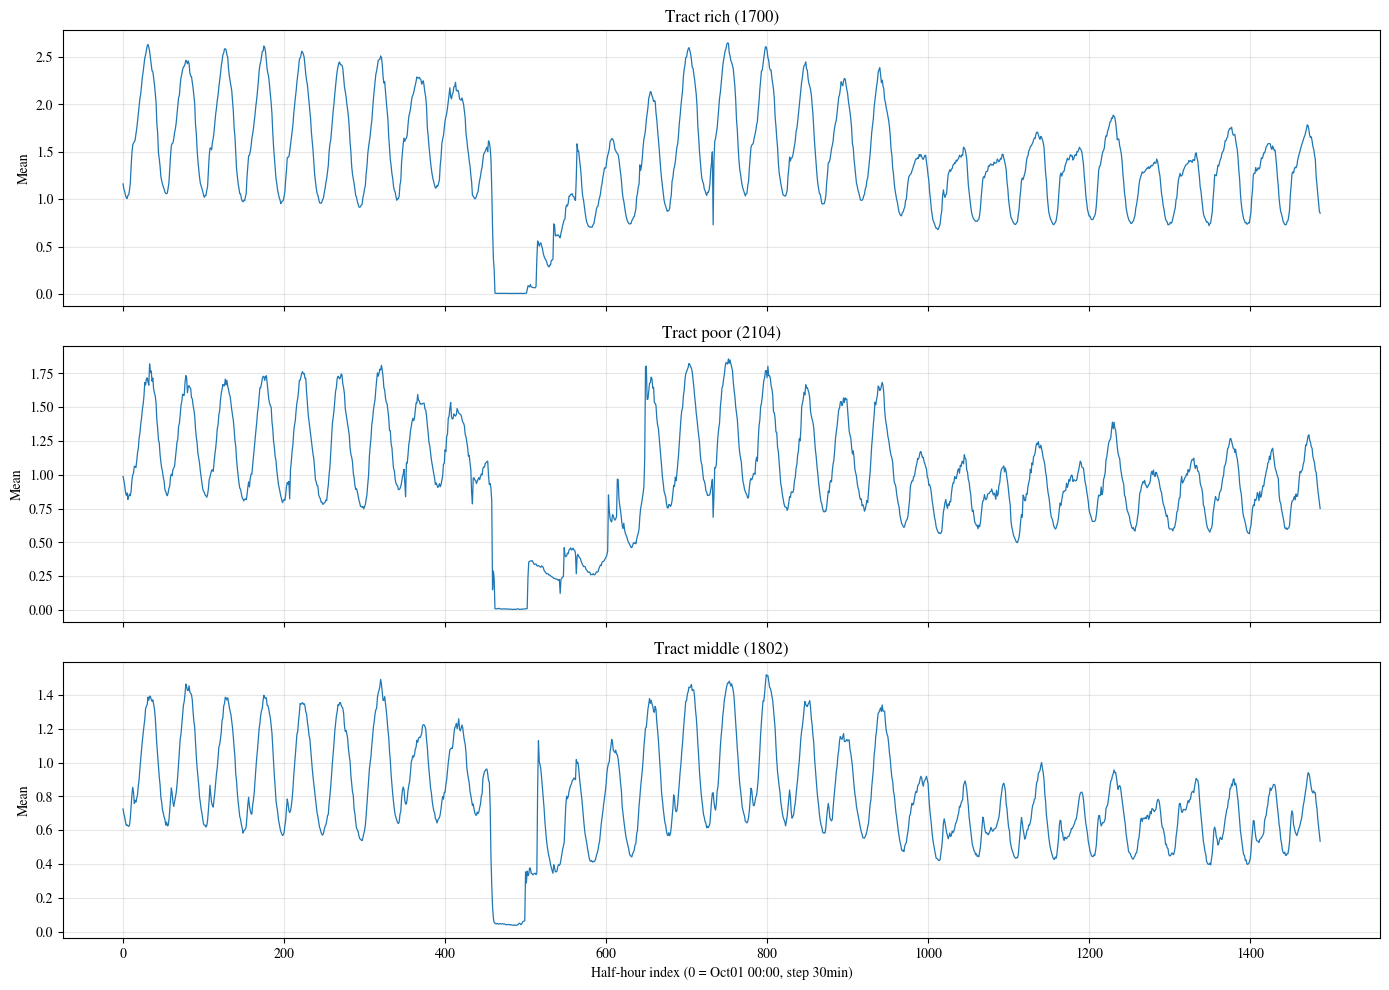

In [13]:
import re
import numpy as np
import matplotlib.pyplot as plt
def oct_h_columns(df: pd.DataFrame, prefix: str = "oct_h") -> list[str]:
    cols = [c for c in df.columns if c.startswith(prefix)]
    # oct_h0000, ..., oct_h1487 按序号排
    return sorted(cols, key=lambda c: int(re.search(r"oct_h(\d+)", c).group(1)))
def mean_profile(df: pd.DataFrame) -> np.ndarray:
    cols = oct_h_columns(df)
    if not cols:
        raise ValueError("未找到 oct_h 列")
    X = df[cols].to_numpy(dtype=float)
    return np.nanmean(X, axis=0)
def plot_three_tracts(df_rich, df_poor, df_mid, titles=None):
    if titles is None:
        titles = ["Tract rich (1700)", "Tract poor (2104)", "Tract middle (1802)"]
    series = [mean_profile(df_rich), mean_profile(df_poor), mean_profile(df_mid)]
    x = np.arange(len(series[0]))
    fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
    for ax, y, t in zip(axes, series, titles):
        ax.plot(x, y, lw=0.9, color="C0")
        ax.set_ylabel("Mean")
        ax.set_title(t)
        ax.grid(True, alpha=0.3)
    axes[-1].set_xlabel("Half-hour index (0 = Oct01 00:00, step 30min)")
    plt.tight_layout()
    plt.show()
plot_three_tracts(
    df_tract_rich_half_hour,
    df_tract_poor_half_hour,
    df_tract_middle_half_hour,
)

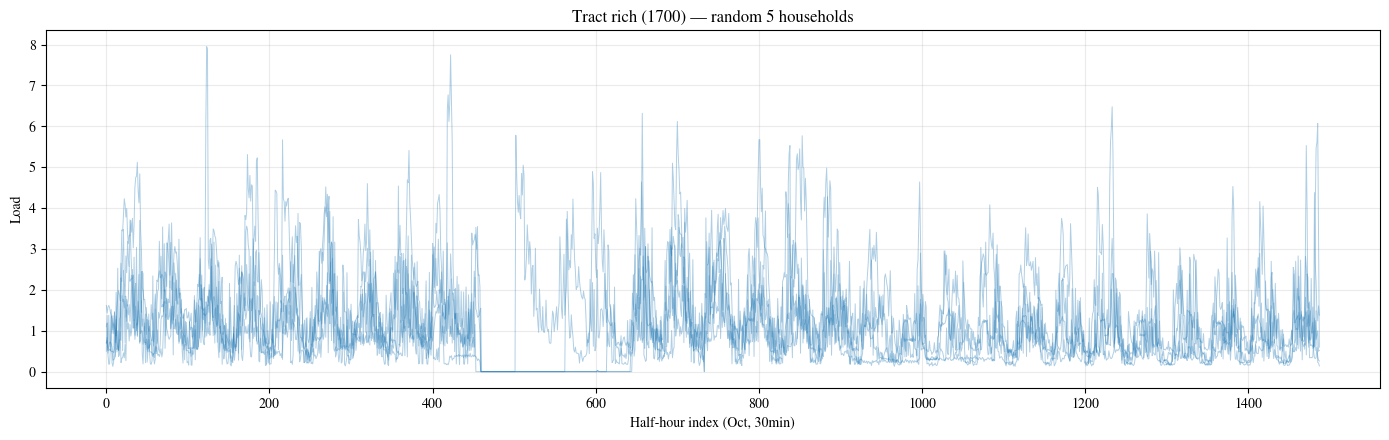

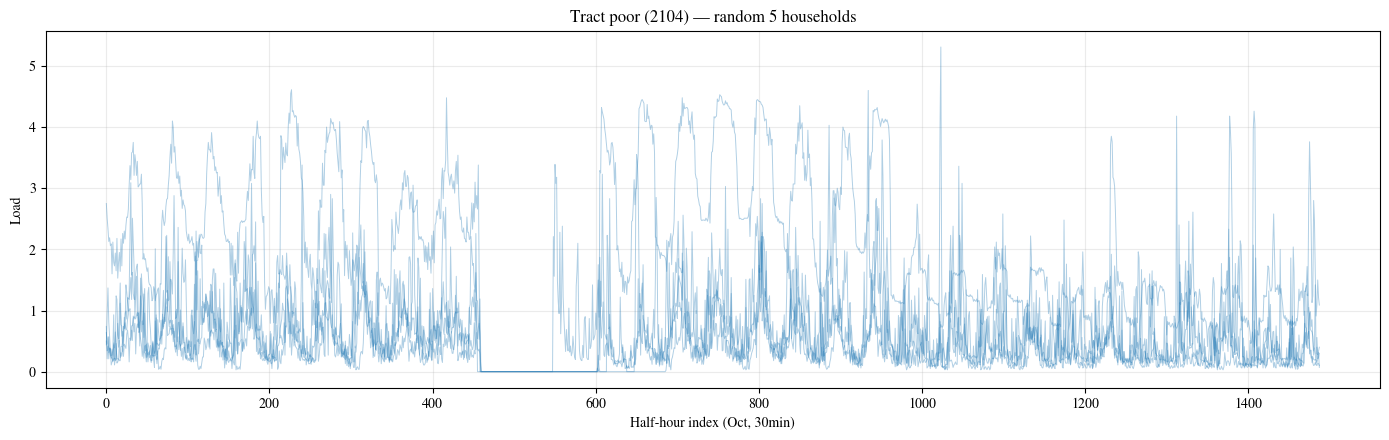

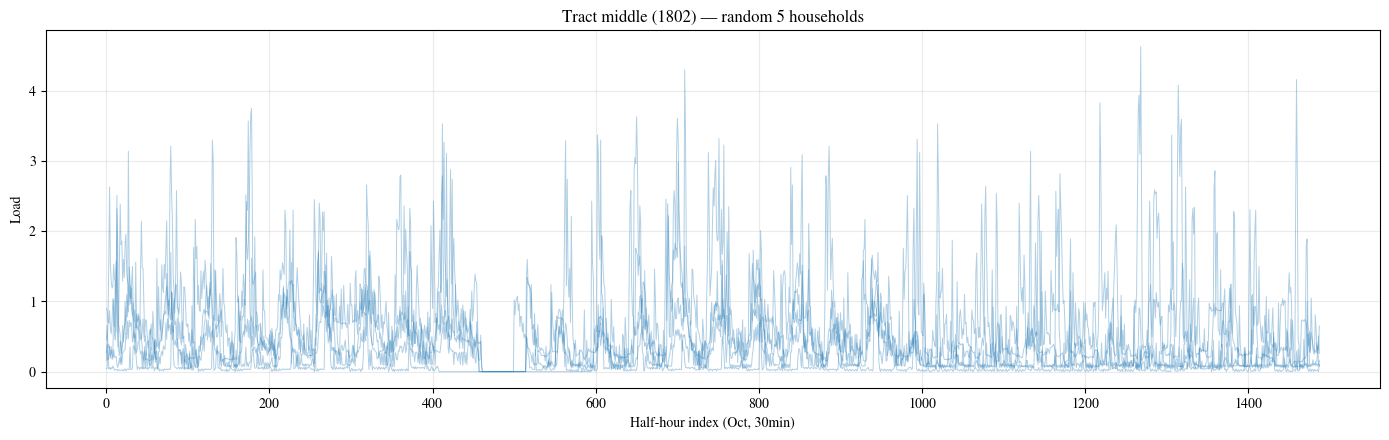

In [16]:
import re
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
def oct_h_columns(df: pd.DataFrame, prefix: str = "oct_h") -> list[str]:
    cols = [c for c in df.columns if c.startswith(prefix)]
    return sorted(cols, key=lambda c: int(re.search(r"oct_h(\d+)", c).group(1)))
def plot_tract_sample_curves(
    df: pd.DataFrame,
    title: str,
    n: int = 10,
    random_state: int | None = 0,
    alpha: float = 0.35,
    lw: float = 0.7,
):
    cols = oct_h_columns(df)
    if not cols:
        raise ValueError("未找到 oct_h 列")
    n_draw = min(n, len(df))
    if n_draw == 0:
        print(f"[{title}] 无数据，跳过")
        return
    samp = df.sample(n=n_draw, random_state=random_state)
    X = samp[cols].to_numpy(dtype=float)
    x = np.arange(X.shape[1])
    plt.figure(figsize=(14, 4.5))
    for row in X:
        plt.plot(x, row, color="C0", alpha=alpha, lw=lw)
    plt.title(f"{title} — random {n_draw} households")
    plt.xlabel("Half-hour index (Oct, 30min)")
    plt.ylabel("Load")
    plt.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.show()
N = 5  # 想抽多少户就改这里
RNG = None  # 随机种子，可改 None 每次不同
plot_tract_sample_curves(
    df_tract_rich_half_hour, "Tract rich (1700)", n=N, random_state=RNG
)
plot_tract_sample_curves(
    df_tract_poor_half_hour, "Tract poor (2104)", n=N, random_state=RNG
)
plot_tract_sample_curves(
    df_tract_middle_half_hour, "Tract middle (1802)", n=N, random_state=RNG)

In [19]:
import re
import numpy as np
import pandas as pd

DAYS = 31
HALF_PER_DAY = 48
BLOCKS_PER_DAY = 6    # 每天 6 个 4 小时块
HALF_PER_BLOCK = 8    # 每块 8 个半小时

def oct_h_sorted_columns(df: pd.DataFrame, prefix: str = "oct_h") -> list[str]:
    cols = [c for c in df.columns if c.startswith(prefix)]
    return sorted(cols, key=lambda c: int(re.search(r"oct_h(\d+)", c).group(1)))

def half_hour_wide_to_four_hour(
    df: pd.DataFrame,
    meta_cols: list[str] | None = None,
    oct_prefix: str = "oct_h",
    out_prefix: str = "oct_4h",
) -> pd.DataFrame:
    """
    宽表：badge + oct_h*（1488） → badge + meta + oct_4h*（186）
    每个 4 小时块 = 当日连续 8 个半点之和。
    """
    cols = oct_h_sorted_columns(df, oct_prefix)
    if len(cols) != DAYS * HALF_PER_DAY:
        raise ValueError(f"期望 {DAYS * HALF_PER_DAY} 个半点列，实际 {len(cols)}")

    if meta_cols is None:
        meta_cols = [c for c in df.columns if not c.startswith(oct_prefix)]

    X = df[cols].to_numpy(dtype=float)
    n = X.shape[0]
    Xd = X.reshape(n, DAYS, HALF_PER_DAY)
    X4h = Xd.reshape(n, DAYS, BLOCKS_PER_DAY, HALF_PER_BLOCK).sum(axis=-1)
    flat = X4h.reshape(n, DAYS * BLOCKS_PER_DAY)
    out_cols = [f"{out_prefix}_{i:04d}" for i in range(DAYS * BLOCKS_PER_DAY)]
    out_num = pd.DataFrame(flat, columns=out_cols, index=df.index)
    meta = df[meta_cols].copy()
    return pd.concat([meta, out_num], axis=1)

META = ["badge", "halfhour_missing_ratio", "halfhour_zero_ratio"]
META = [c for c in META if c in df_tract_rich_half_hour.columns]

df_tract_rich_four_hour = half_hour_wide_to_four_hour(
    df_tract_rich_half_hour.rename(columns={}),
    meta_cols=META,
)
df_tract_poor_four_hour = half_hour_wide_to_four_hour(
    df_tract_poor_half_hour,
    meta_cols=[c for c in META if c in df_tract_poor_half_hour.columns],
)
df_tract_middle_four_hour = half_hour_wide_to_four_hour(
    df_tract_middle_half_hour,
    meta_cols=[c for c in META if c in df_tract_middle_half_hour.columns],
)

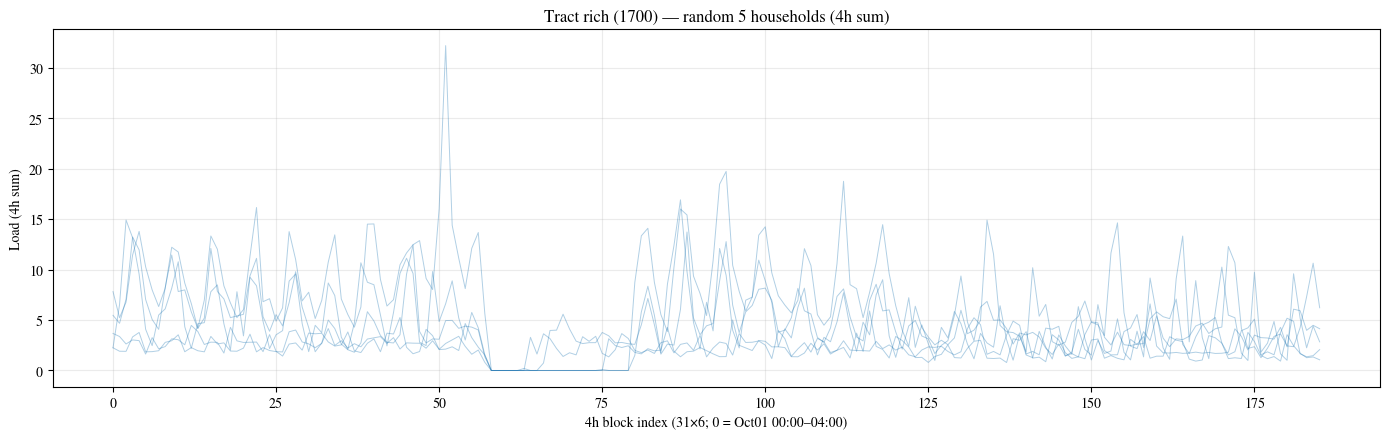

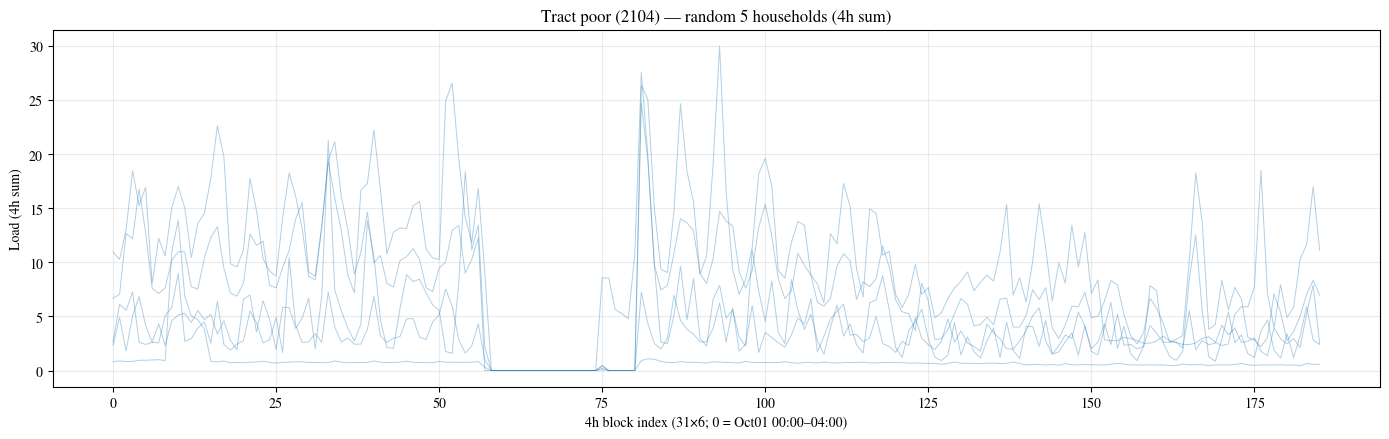

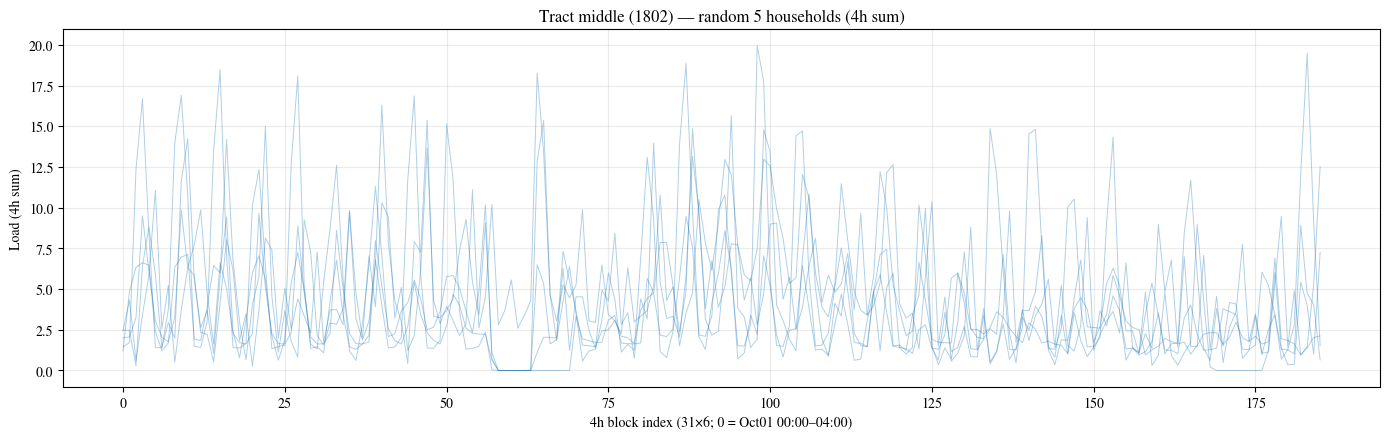

In [21]:
import re
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

def oct_4h_columns(df: pd.DataFrame, prefix: str = "oct_4h") -> list[str]:
    cols = [c for c in df.columns if c.startswith(prefix)]
    return sorted(cols, key=lambda c: int(re.search(r"oct_4h_(\d+)", c).group(1)))

def plot_tract_sample_curves_four_hour(
    df: pd.DataFrame,
    title: str,
    n: int = 10,
    random_state: int | None = 0,
    alpha: float = 0.35,
    lw: float = 0.7,
):
    cols = oct_4h_columns(df)
    if not cols:
        raise ValueError("未找到 oct_4h 列")
    n_draw = min(n, len(df))
    if n_draw == 0:
        print(f"[{title}] 无数据，跳过")
        return
    samp = df.sample(n=n_draw, random_state=random_state)
    X = samp[cols].to_numpy(dtype=float)
    x = np.arange(X.shape[1])
    plt.figure(figsize=(14, 4.5))
    for row in X:
        plt.plot(x, row, color="C0", alpha=alpha, lw=lw)
    plt.title(f"{title} — random {n_draw} households (4h sum)")
    plt.xlabel("4h block index (31×6; 0 = Oct01 00:00–04:00)")
    plt.ylabel("Load (4h sum)")
    plt.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.show()

N = 5
RNG = None
plot_tract_sample_curves_four_hour(
    df_tract_rich_four_hour, "Tract rich (1700)", n=N, random_state=RNG
)
plot_tract_sample_curves_four_hour(
    df_tract_poor_four_hour, "Tract poor (2104)", n=N, random_state=RNG
)
plot_tract_sample_curves_four_hour(
    df_tract_middle_four_hour, "Tract middle (1802)", n=N, random_state=RNG
)